In [2]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../'))
sys.path.append(base_path)


import numpy as np
import tensorflow as tf

import project_images_loader as pil
import utils.functions as fc
import utils.nifti_functions as nfc
import utils.visualization as vis
import utils.util_deep_learning as udl

import discriminator as Discriminator
import generator as Generator
# import feature_extractor as feature_extractor

tf.keras.backend.set_image_data_format("channels_first")


pil.SERVER = True

2024-05-06 01:11:25.879368: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-05-06 01:11:26.088248: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-05-06 01:11:27.205226: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /cluster/home/agustinc/miniconda3/envs/s4_old/lib:
2024-05-06 01:11:27.205483: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer_plugin.so.7'; dlerror: lib

SERVER: True


/cluster/home/agustinc/miniconda3/envs/s4_old/lib/python3.9/site-packages/tensorflow_addons/utils/tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(
/cluster/home/agustinc/miniconda3/envs/s4_old/lib/python3.9/site-packages/tensorflow_addons/utils/ensure_tf_install.py:53: UserWarning: Tensorflow Addons supports using Python ops for all Tensorflow versions above or equal to 2.13.0 and strictly below 2.16.0 (nightly versions are not supported). 
 The versions of TensorFlow you are currently using is 2.10.1 and is not supported. 
Some things might work, some things might not.
If you were to enco

INFO:tensorflow:Mixed precision compatibility check (mixed_float16): OK
Your GPU will likely run quickly with dtype policy mixed_float16 as it has compute capability of at least 7.0. Your GPU: NVIDIA A100-PCIE-40GB, compute capability 8.0


In [3]:
input_shape = (192,224,192)

G = Generator.create_generator_model(input_shape)

checkpoint_dir = f"{current_path}/models/training_checkpoints/"
checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
checkpoint = tf.train.Checkpoint(G=G)
# checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir))



2024-05-06 01:11:31.067521: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-05-06 01:11:32.003808: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1616] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 38206 MB memory:  -> device: 0, name: NVIDIA A100-PCIE-40GB, pci bus id: 0000:82:00.0, compute capability: 8.0


In [4]:
def save_image(id, img_gen, img_path_name):
    _, affine = pil.load_preprocessed_image(3, id, absolute=True)
    pil.save_image(img_gen.astype(np.float32), affine, img_path_name)

def generate_image(id, G):   
    img_hunt3, _ = pil.load_preprocessed_image(3, id, absolute=True)
    img_hunt4, _ = pil.load_preprocessed_image(4, id, absolute=True)

    img_gen = G(udl.prepare_img_for_gan(img_hunt3, axis_channels=1), training=False)
    img_gen = udl.recover_img_from_gan(img_gen, axis_channels=1)
    return img_hunt3, img_hunt4, img_gen


-------- Checkpoint: 31
ID: 08202


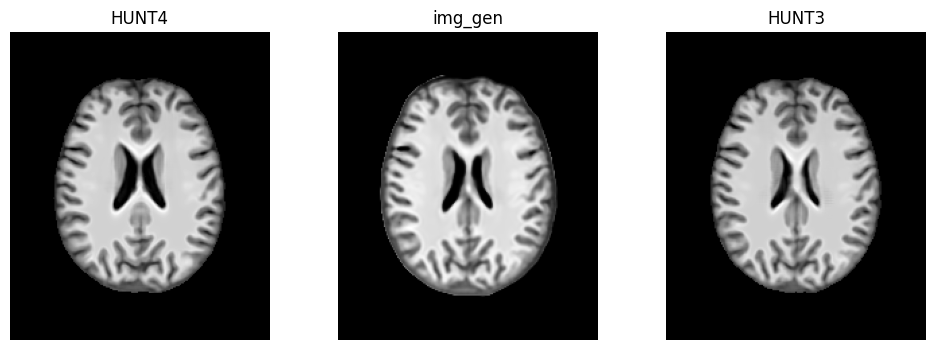

In [6]:
current_plane = 116

matching_ids = pil.get_matching_ids()
id_indexs = [366]
images_list = []
# for checkpoint_index in range(27, 35):
for checkpoint_index in [31]:
    print(f"-------- Checkpoint: {checkpoint_index}")
    checkpoint.restore(f"{checkpoint_dir}/ckpt-{checkpoint_index}")
    # checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir))

    for id_index in id_indexs:
        id = matching_ids[id_index]
        print(f"ID: {id}")

        img_hunt3, img_hunt4, img_gen = generate_image(id, G)
        vis.shows_3_images(img_hunt3, img_hunt4, img_gen, current_plane=current_plane)
        # vis.show_rg_img(img_hunt4, img_gen, "HUNT4 vs Generated")

        # save image
        # img_path_name = f"{current_path}/images/first_results/{id}_CHECK_{checkpoint_index}.nii.gz"
        # save_image(id, img_gen, checkpoint_index)

